# Final ForMa localization visualizations

Compare Photoshop/Firefly (PS-sp) and Stable Diffusion 2 (SD2-sp), using the per-image workbook underlying the final documentation tables. Category comparisons use **grouped bar charts**; histograms below show the distributions of per-image scores.

Run in the ForMa Python environment. If plotting dependencies are missing, run `%pip install matplotlib pandas openpyxl ipykernel` in a separate cell, then restart the kernel. Model examples require the existing ForMa dependencies and released checkpoint. This notebook reads the workbook without changing it and saves figures under `results/final_visualizations/`.

The qualitative panels show the **manipulated input photograph**, its true mask, and ForMa output. Authentic pre-manipulation originals are not present in the local dataset folders. Best/worst examples are deliberately selected extremes, not representative random samples.

In [50]:
!pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable


In [51]:
import sys
print(sys.executable)


c:\Users\PC CABA DZ\DRAIEVAL\Group8_Benchmarking_inpainting_detection_with_small_models\.venv\Scripts\python.exe


In [52]:
import subprocess
import sys

subprocess.check_call([
    "uv", "pip", "install",
    "--python", sys.executable,
    "matplotlib",
])

0

In [53]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


c:\Users\PC CABA DZ\DRAIEVAL\Group8_Benchmarking_inpainting_detection_with_small_models\.venv\Scripts\python.exe: No module named pip


In [54]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [Path.cwd(), Path.cwd() / 'ForMa',
              Path.cwd() / 'Group8_Benchmarking_inpainting_detection_with_small_models' / 'ForMa']
FORMA_DIR = next((p.resolve() for p in candidates if (p / 'inference.py').is_file()), None)
if FORMA_DIR is None:
    raise FileNotFoundError('Launch from ForMa, the project root, or workspace; otherwise set FORMA_DIR.')
WORKBOOK = FORMA_DIR / 'results/results_excel.xlsx'
# These identify the completed runs used in the final documentation tables.
EVALUATIONS = {
    'PS-sp': 'bce894a835eecfa44c2cea8272f14c3ba7bfb64ba11efcd5d1c4544c4d29b7b0',
    'SD2-sp': 'bd5b2f0d76759cb101333c655ca249a21a5db2ed7e1c76efe640a8831251c10a',
}
raw = pd.read_excel(WORKBOOK, sheet_name='images', dtype={'source_id': str})
parts = []
for subset, evaluation_id in EVALUATIONS.items():
    part = raw.loc[(raw.subset == subset) & (raw.evaluation_id == evaluation_id)]
    if part.empty:
        display(raw.groupby(['subset', 'evaluation_id']).size().rename('images'))
        raise ValueError(f'Missing selected evaluation for {subset}; update EVALUATIONS explicitly.')
    parts.append(part)
df = pd.concat(parts, ignore_index=True)
keys = ['category', 'source_id', 'mask_type', 'variant']
if df.duplicated(['subset', *keys]).any():
    raise ValueError('Duplicate logical samples in selected evaluations.')
a, b = [set(map(tuple, part[keys].to_numpy())) for part in parts]
if a != b:
    raise ValueError('Generator evaluations do not contain identical source/type/variant combinations.')
for field in ['checkpoint_sha256', 'input_size', 'prediction_threshold', 'ground_truth_threshold', 'postprocessing']:
    if df[field].nunique() != 1:
        raise ValueError(f'Incompatible evaluation settings: {field}')
METRICS = ['pixel_f1', 'recall', 'precision', 'iou', 'dice', 'specificity', 'pixel_accuracy']
LABELS = dict(pixel_f1='F1', recall='Recall', precision='Precision', iou='IoU',
              dice='Dice', specificity='Specificity', pixel_accuracy='Pixel accuracy')
SUBSETS = list(EVALUATIONS)
COLORS = ['#2563eb', '#ea580c']
NAMES = {'PS-sp': 'Photoshop / Firefly', 'SD2-sp': 'Stable Diffusion 2'}
FIG_DIR = FORMA_DIR / 'results/final_visualizations'
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'{name}.png', dpi=180, bbox_inches='tight')
    plt.show()

means = df.groupby(['category', 'subset'])[METRICS].mean()
summary = df.groupby(['category', 'subset']).agg(Images=('source_id', 'size'), Sources=('source_id', 'nunique')).join(means)
display(summary.rename(columns=LABELS).round(4))
print('Undefined scores excluded per metric:')
display(df.groupby('subset')[METRICS].agg(lambda x: x.isna().sum()))
print('Counts by generator and mask type:')
display(df.groupby(['subset', 'mask_type']).size().unstack())

Images  Sources      F1  Recall  Precision     IoU  \
category      subset                                                       
airplane      PS-sp      168       28  0.4318  0.3910     0.6632  0.3228   
              SD2-sp     168       28  0.4856  0.4755     0.6301  0.3941   
bear          PS-sp      120       20  0.4648  0.3993     0.7038  0.3452   
              SD2-sp     120       20  0.3449  0.3018     0.5154  0.2570   
elephant      PS-sp      210       35  0.4354  0.3562     0.6768  0.3246   
              SD2-sp     210       35  0.2745  0.2295     0.4793  0.1981   
hair-drier    PS-sp       12        2  0.4103  0.3287     0.6280  0.2700   
              SD2-sp      12        2  0.1552  0.1213     0.3354  0.0950   
kite          PS-sp      186       31  0.3488  0.3156     0.6081  0.2413   
              SD2-sp     186       31  0.2872  0.2726     0.4682  0.2095   
scissors      PS-sp       54        9  0.1444  0.1518     0.2057  0.0939   
              SD2-sp      54        9  0.1501  0.1287     0.2476  0.1021   
sheep         PS-sp      168       28  0.3079  0.2788     0.5111  0.2165   
              SD2-sp     168       28  0.2119  0.1882     0.4029  0.1420   
skis          PS-sp      264       44  0.0985  0.1571     0.1146  0.0615   
              SD2-sp     264       44  0.0828  0.1385     0.0963  0.0498   
snowboard     PS-sp      120       20  0.2170  0.3505     0.2094  0.1444   
              SD2-sp     120       20  0.1898  0.3114     0.1765  0.1235   
sports-ball   PS-sp      132       22  0.2458  0.3819     0.2536  0.1819   
              SD2-sp     132       22  0.2549  0.3923     0.2425  0.2000   
stop-sign     PS-sp      120       20  0.6128  0.5648     0.8029  0.4773   
              SD2-sp     120       20  0.5193  0.4992     0.6945  0.4109   
tennis-racket PS-sp      282       47  0.2207  0.3479     0.2331  0.1474   
              SD2-sp     282       47  0.1769  0.3019     0.1730  0.1171   
zebra         PS-sp      222       37  0.3557  0.3085     0.5777  0.2487   
              SD2-sp     222       37  0.2527  0.2327     0.3898  0.1759   

                        Dice  Specificity  Pixel accuracy  
category      subset                                       
airplane      PS-sp   0.4318       0.9735          0.9412  
              SD2-sp  0.4856       0.9700          0.9449  
bear          PS-sp   0.4648       0.9797          0.9088  
              SD2-sp  0.3449       0.9582          0.8801  
elephant      PS-sp   0.4354       0.9895          0.9073  
              SD2-sp  0.2745       0.9776          0.8814  
hair-drier    PS-sp   0.4103       0.9851          0.9253  
              SD2-sp  0.1552       0.9813          0.9056  
kite          PS-sp   0.3488       0.9831          0.9464  
              SD2-sp  0.2872       0.9751          0.9390  
scissors      PS-sp   0.1444       0.9639          0.9193  
              SD2-sp  0.1501       0.9700          0.9231  
sheep         PS-sp   0.3079       0.9844          0.9269  
              SD2-sp  0.2119       0.9775          0.9144  
skis          PS-sp   0.0985       0.9691          0.9481  
              SD2-sp  0.0828       0.9688          0.9460  
snowboard     PS-sp   0.2170       0.9615          0.9471  
              SD2-sp  0.1898       0.9586          0.9438  
sports-ball   PS-sp   0.2458       0.9541          0.9420  
              SD2-sp  0.2549       0.9562          0.9446  
stop-sign     PS-sp   0.6128       0.9886          0.9520  
              SD2-sp  0.5193       0.9790          0.9354  
tennis-racket PS-sp   0.2207       0.9608          0.9456  
              SD2-sp  0.1769       0.9587          0.9429  
zebra         PS-sp   0.3557       0.9750          0.8912  
              SD2-sp  0.2527       0.9623          0.8754

Undefined scores excluded per metric:


,pixel_f1,recall,precision,iou,dice,specificity,pixel_accuracy
subset,,,,,,,
PS-sp,0,0,0,0,0,0,0
SD2-sp,0,0,0,0,0,0,0


Counts by generator and mask type:


mask_type,bbox,segm
subset,,
PS-sp,1029,1029
SD2-sp,1029,1029


## Grouped macro scores for all 13 categories

Each score is a mean across defined per-image scores, combining bounding-box and segmentation examples. Every image has equal weight within its category. Metrics use a fixed 0-1 axis. F1 and Dice are identical in this evaluator, but both are displayed to match the report. These are descriptive estimates without confidence intervals.

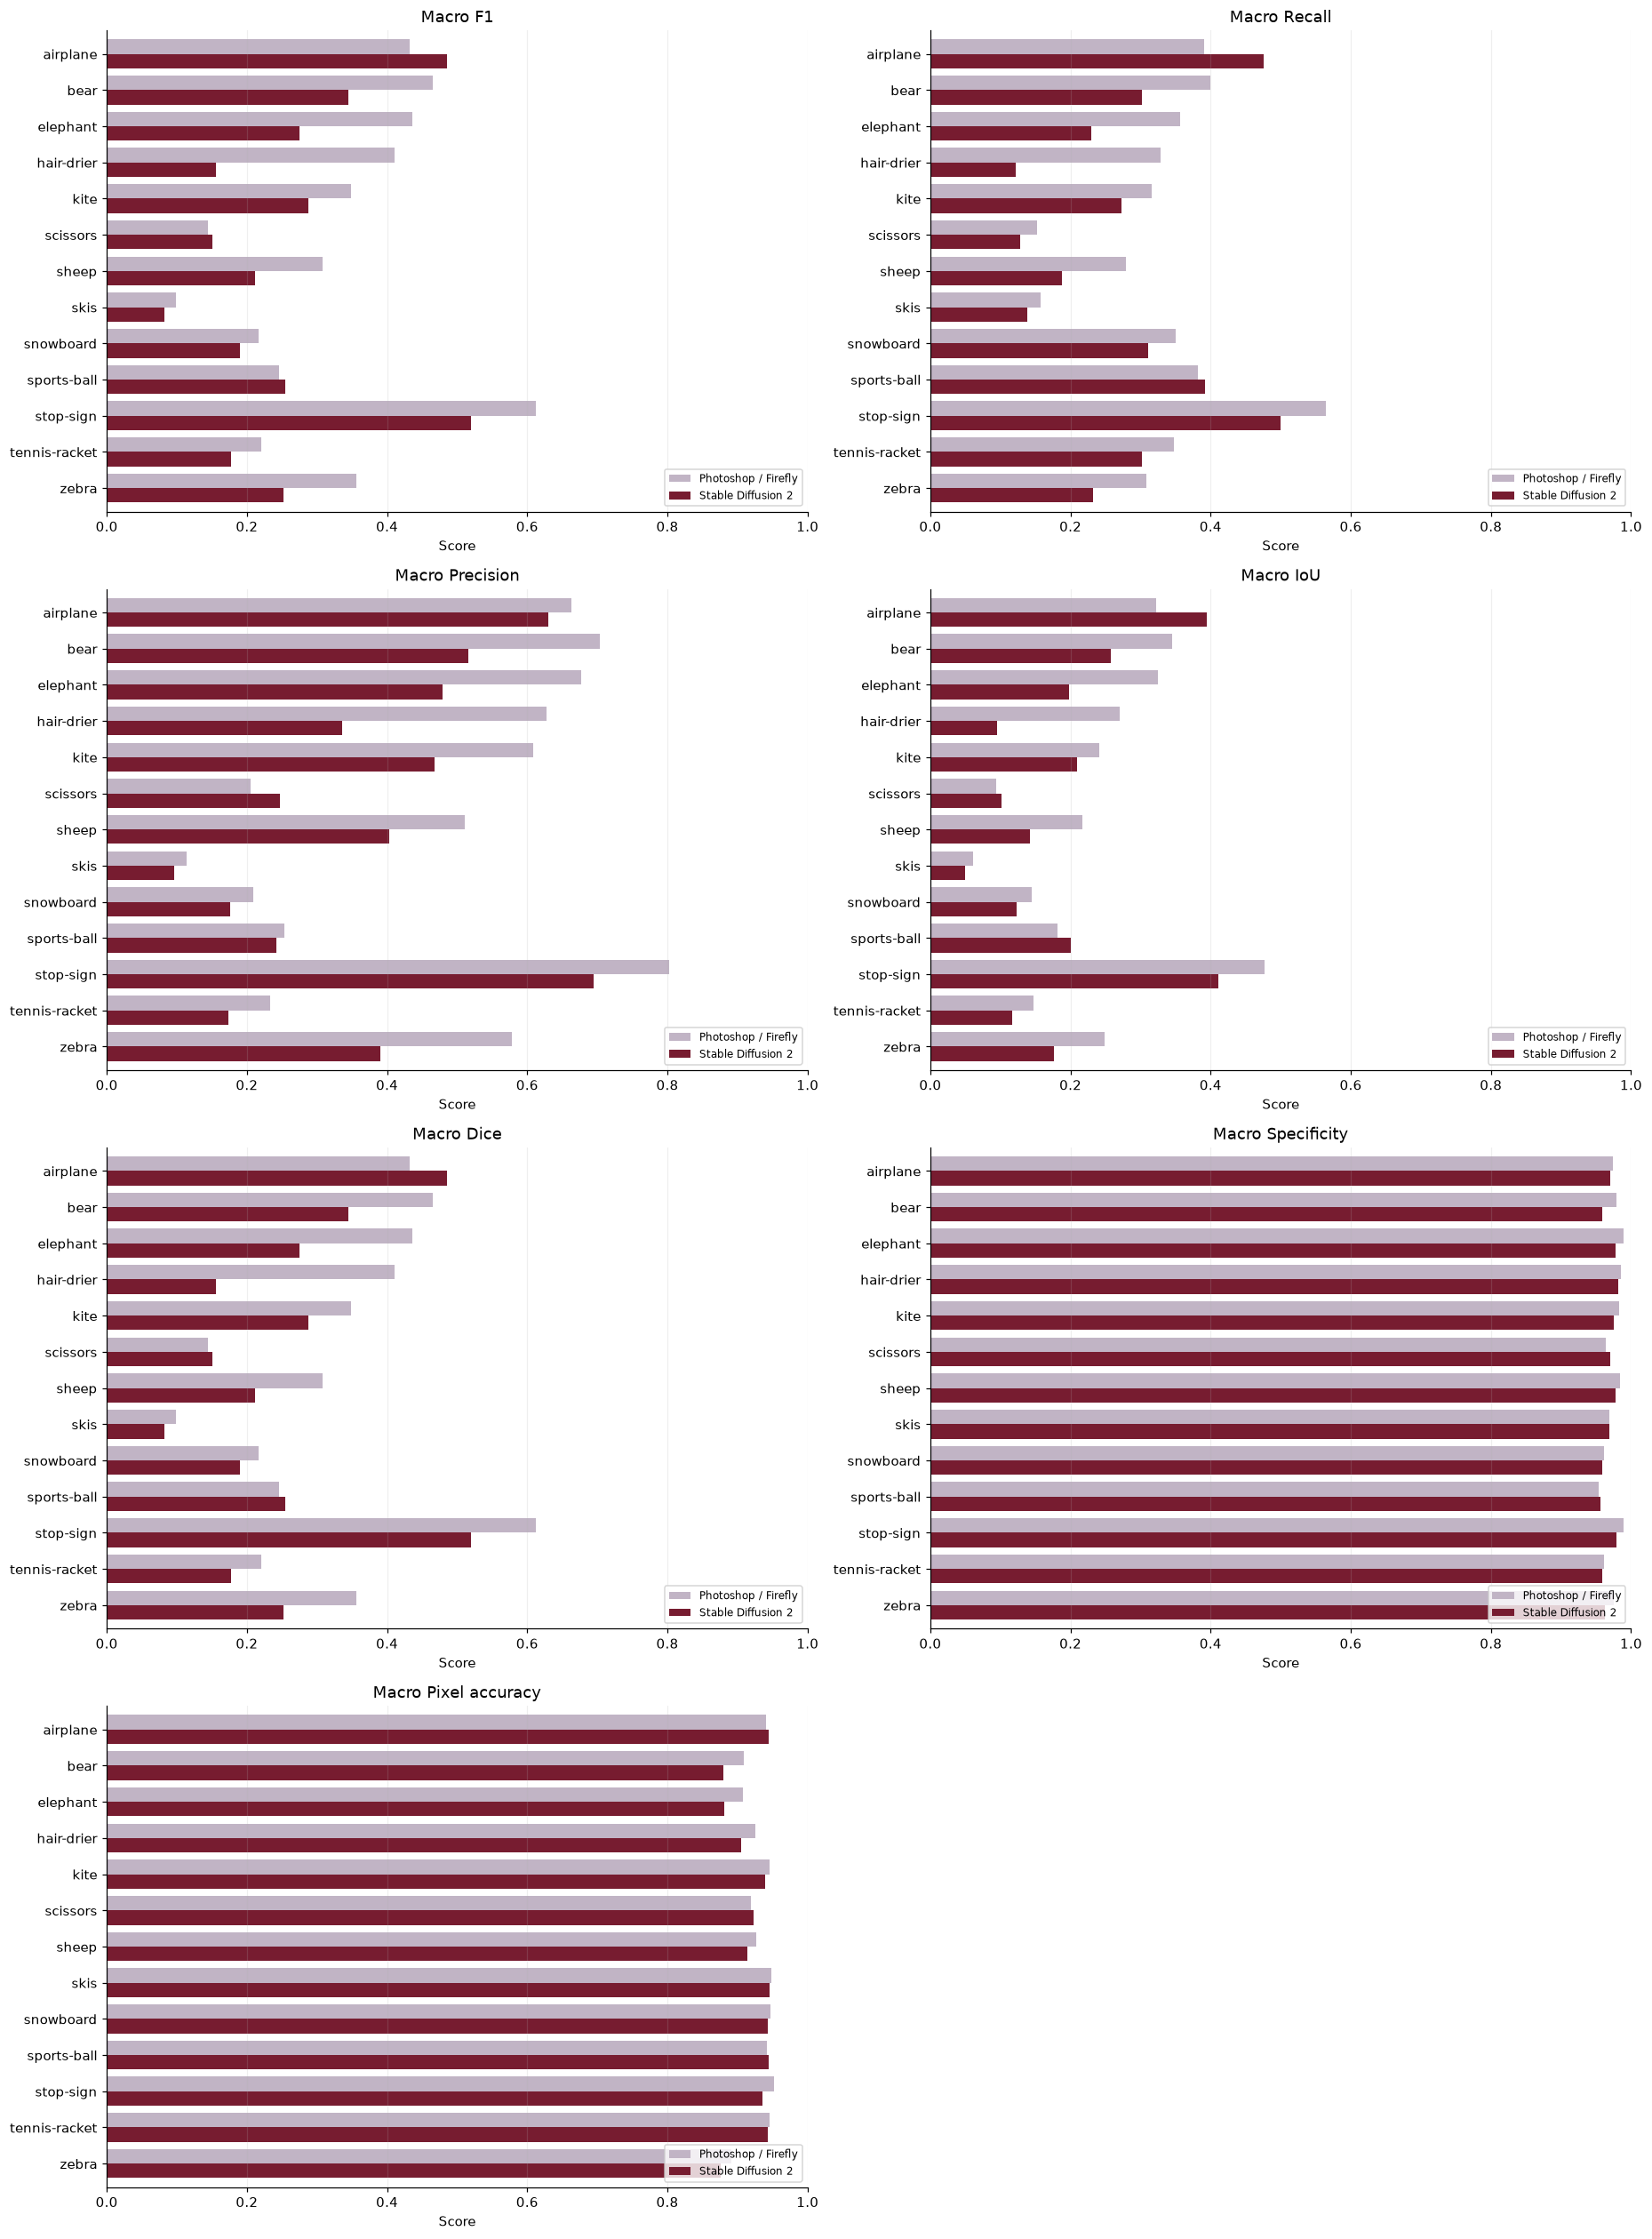

In [55]:
COLORS = ['#c1b4c5', '#771c30']
order = sorted(df.category.unique())
fig, axes = plt.subplots(4, 2, figsize=(17, 23))
for ax, metric in zip(axes.flat, METRICS):
    table = means[metric].unstack('subset').reindex(index=order, columns=SUBSETS)
    table.rename(columns=NAMES).plot.barh(ax=ax, color=COLORS, width=.8)
    ax.set(title=f'Macro {LABELS[metric]}', xlabel='Score', ylabel='', xlim=(0, 1))
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=.2)
    ax.legend(fontsize=8, loc='lower right')
axes.flat[-1].axis('off')
finish(fig, 'category_all_metrics_grouped')

## Overall generator comparison

Equal-image means give more influence to larger categories. Equal-category means give each category equal weight. Neither is a pooled-pixel micro score. Undefined values are omitted per metric, including entirely undefined categories in the equal-category mean.

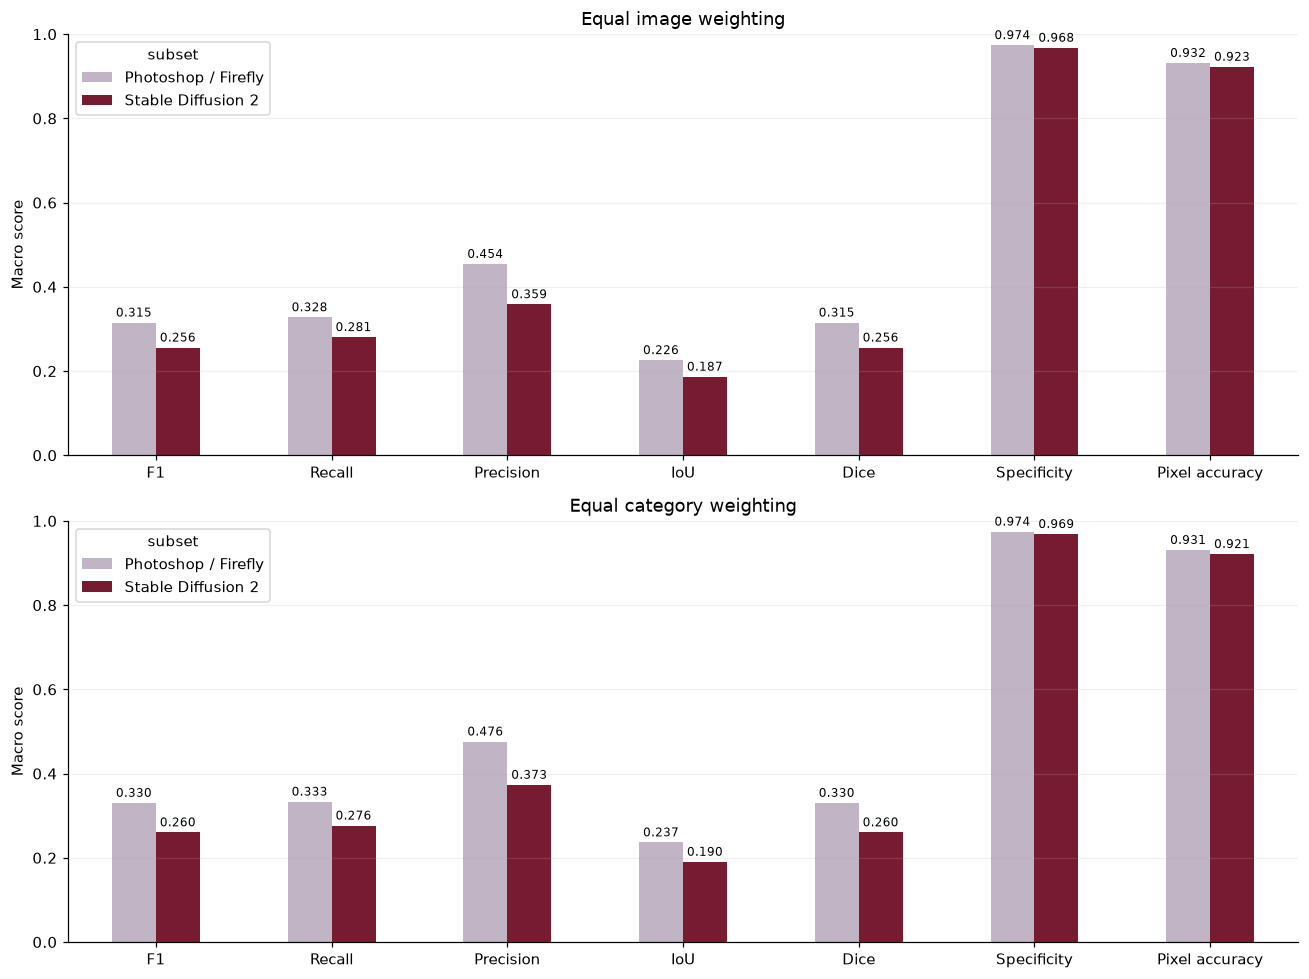

F1  Recall  Precision     IoU    Dice  \
Aggregation           subset                                              
Equal image weight    PS-sp   0.3150  0.3277     0.4542  0.2259  0.3150   
                      SD2-sp  0.2557  0.2806     0.3585  0.1865  0.2557   
Equal category weight PS-sp   0.3303  0.3332     0.4760  0.2366  0.3303   
                      SD2-sp  0.2605  0.2764     0.3732  0.1904  0.2605   

                              Specificity  Pixel accuracy  
Aggregation           subset                               
Equal image weight    PS-sp        0.9739          0.9316  
                      SD2-sp       0.9677          0.9226  
Equal category weight PS-sp        0.9745          0.9309  
                      SD2-sp       0.9687          0.9213

In [56]:
image_means = df.groupby('subset')[METRICS].mean().reindex(SUBSETS)
category_means = means.groupby('subset').mean().reindex(SUBSETS)
fig, axes = plt.subplots(2, 1, figsize=(12, 9))
for ax, table, title in zip(axes, [image_means, category_means], ['Equal image weighting', 'Equal category weighting']):
    table.rename(index=NAMES, columns=LABELS).T.plot.bar(ax=ax, color=COLORS, rot=0)
    ax.set(title=title, ylabel='Macro score', ylim=(0, 1))
    ax.grid(axis='y', alpha=.2)
    for bars in ax.containers:
        ax.bar_label(bars, fmt='%.3f', fontsize=8, padding=2)
finish(fig, 'overall_generator_comparison')
display(pd.concat({'Equal image weight': image_means, 'Equal category weight': category_means}, names=['Aggregation']).rename(columns=LABELS).round(4))

## Histograms and mask-type breakdown

Histogram bars count images in the same score intervals for both generators. Unlike the category bars, these show the spread of individual scores. Related variants are correlated, so counts are not numbers of independent observations.

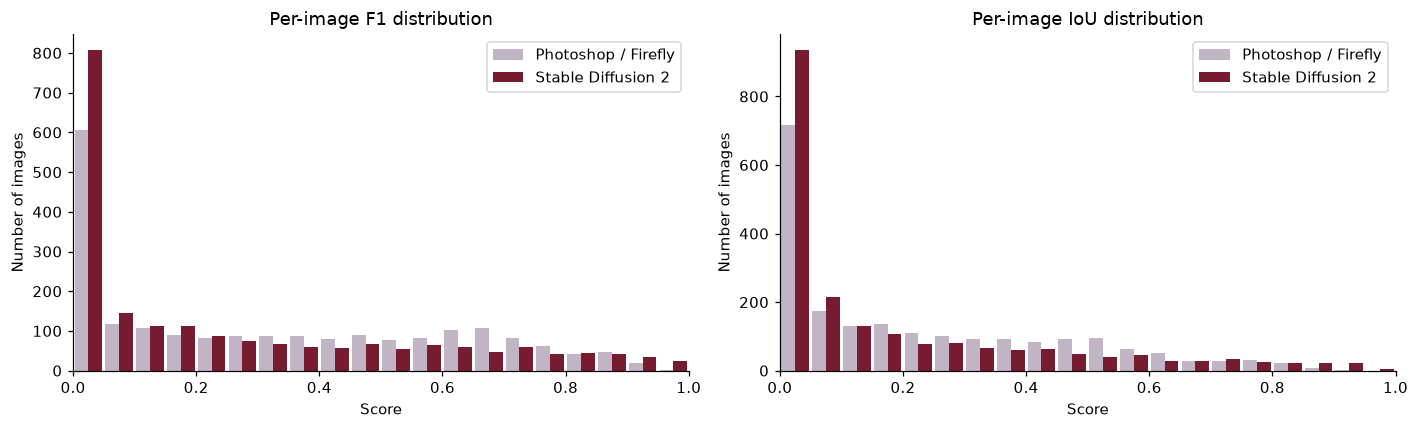

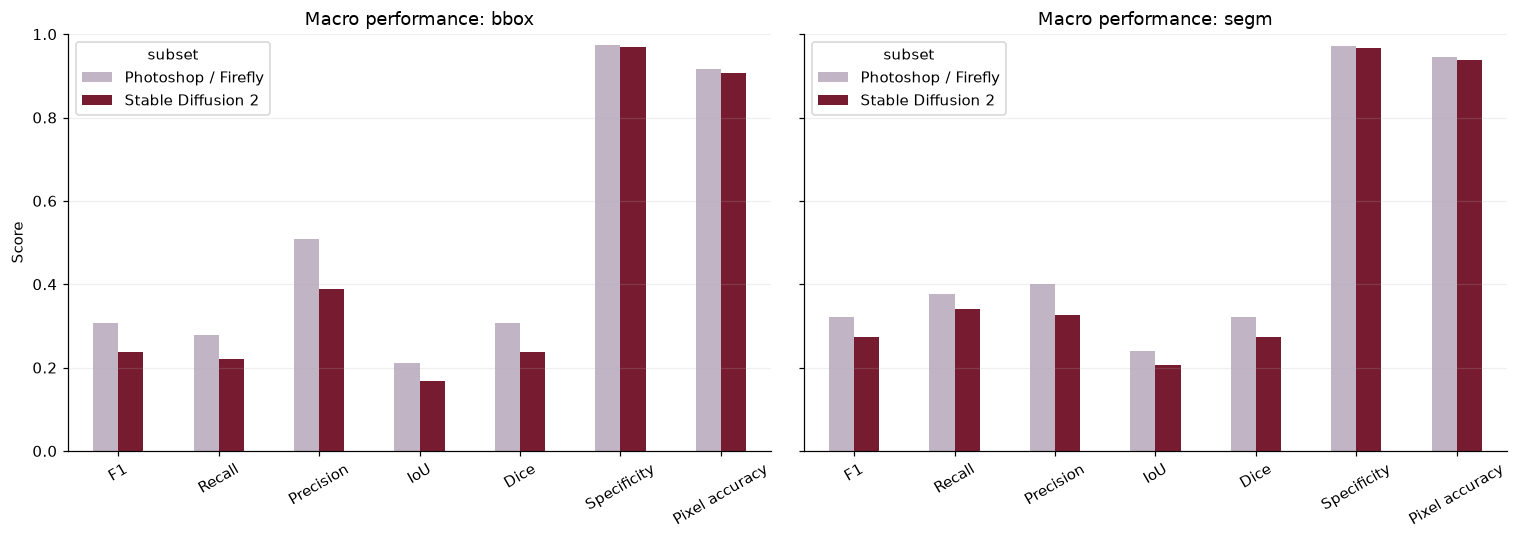

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bins = np.linspace(0, 1, 21)
for ax, metric in zip(axes, ['pixel_f1', 'iou']):
    values = [df.loc[df.subset == subset, metric].dropna().to_numpy() for subset in SUBSETS]
    ax.hist(values, bins=bins, color=COLORS, label=[NAMES[s] for s in SUBSETS], rwidth=.9)
    ax.set(title=f'Per-image {LABELS[metric]} distribution', xlabel='Score', ylabel='Number of images', xlim=(0, 1))
    ax.legend()
finish(fig, 'f1_iou_histograms')

by_type = df.groupby(['mask_type', 'subset'])[METRICS].mean()
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, kind in zip(axes, ['bbox', 'segm']):
    by_type.xs(kind).reindex(SUBSETS).rename(index=NAMES, columns=LABELS).T.plot.bar(ax=ax, color=COLORS, rot=30)
    ax.set(title=f'Macro performance: {kind}', ylabel='Score', ylim=(0, 1))
    ax.grid(axis='y', alpha=.2)
finish(fig, 'mask_type_generator_comparison')

## Best and worst localization examples

Select the highest and lowest **per-image F1** across both selected generator runs. Ties are broken by IoU, then image filename and subset (ascending lexical order). All tied worst cases have the same minimum F1; the displayed failure is just one of them. Set `EXAMPLE_SUBSET` to `PS-sp` or `SD2-sp` to choose extremes within that generator.

The last cell performs actual inference using the recorded settings, checks input/checkpoint hashes, and reports whether all four regenerated confusion counts exactly match the workbook. CPU inference may take a few minutes; matching cached predictions are reused. These deliberately selected best/worst images cannot establish average model performance.

In [58]:
EXAMPLE_SUBSET = None  # None: both generators; alternatively 'PS-sp' or 'SD2-sp'
DEVICE = 'cpu'
WEIGHTS_OVERRIDE = None
pool = df if EXAMPLE_SUBSET is None else df.loc[df.subset == EXAMPLE_SUBSET]
pool = pool.dropna(subset=['pixel_f1', 'iou'])
if pool.empty:
    raise ValueError('No defined examples for the selected subset.')
best = pool.sort_values(['pixel_f1', 'iou', 'image_name', 'subset'], ascending=[False, False, True, True]).head(1).copy()
worst = pool.sort_values(['pixel_f1', 'iou', 'image_name', 'subset'], ascending=[True, True, True, True]).head(1).copy()
best['selection'] = 'Best F1'
worst['selection'] = 'Worst F1'
samples = pd.concat([best, worst], ignore_index=True)
print(f'Candidates: {len(pool)} images; minimum-F1 ties: {(pool.pixel_f1 == pool.pixel_f1.min()).sum()}')
display(samples[['selection', 'subset', 'category', 'source_id', 'mask_type', 'image_name', 'pixel_f1', 'iou']])

Candidates: 4116 images; minimum-F1 ties: 944


,selection,subset,category,source_id,mask_type,image_name,pixel_f1,iou
0,Best F1,SD2-sp,airplane,545407,bbox,545407_mask_bbox.png_ps_mask.png_sd2_1.png,0.983952,0.968412
1,Worst F1,SD2-sp,elephant,105923,bbox,105923_mask_bbox.png_ps_mask.png_sd2_0.png,0.000000,0.000000


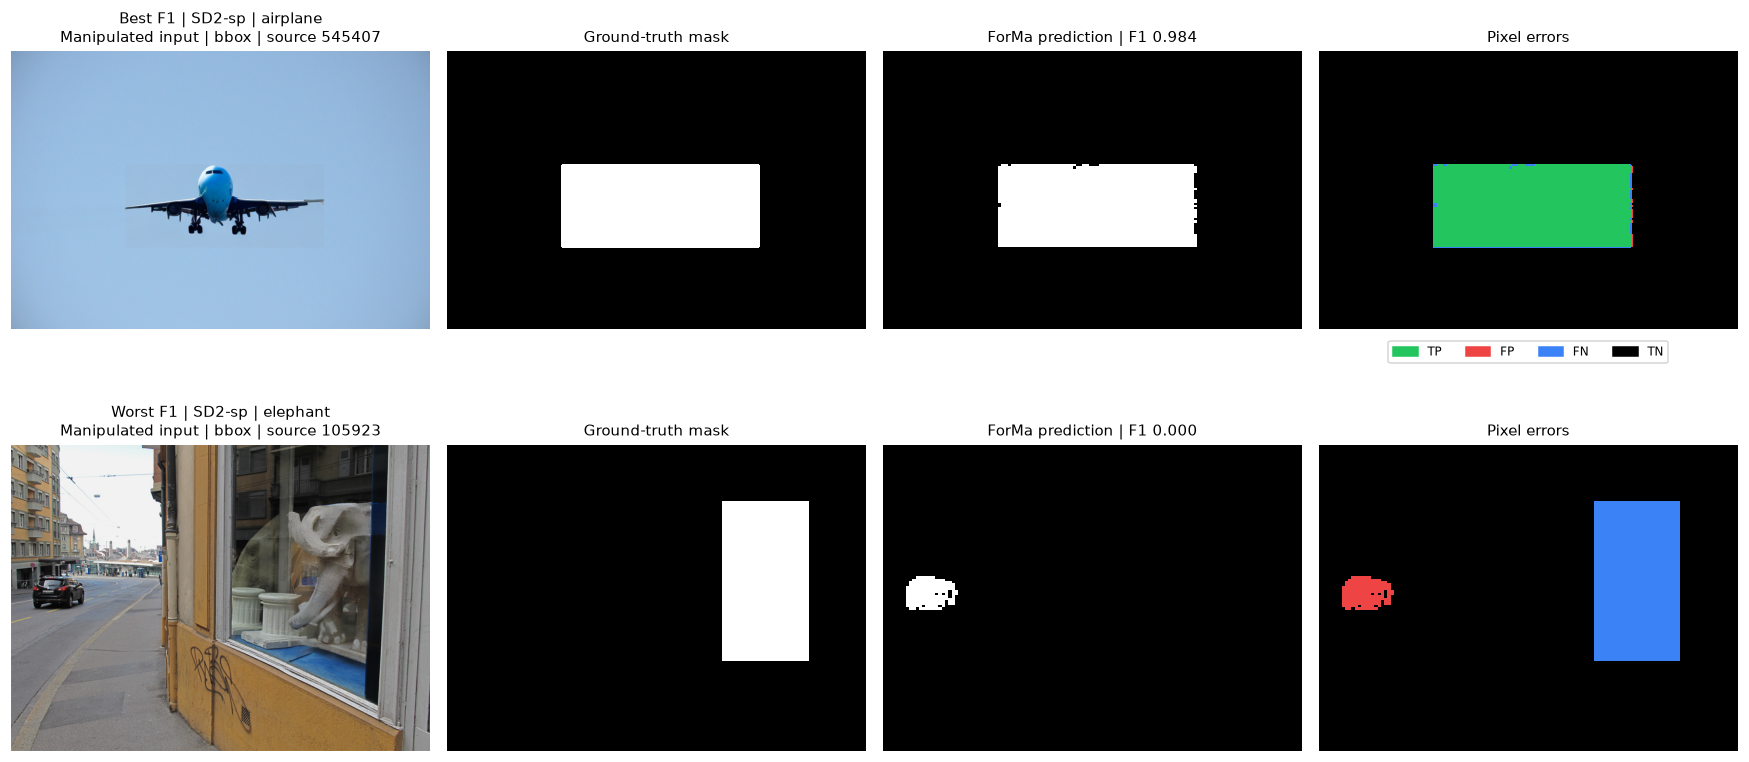

,selection,subset,mask_type,recorded_F1,visualized_F1,exact_counts_match
0,Best F1,SD2-sp,bbox,0.983952,0.983952,True
1,Worst F1,SD2-sp,bbox,0.000000,0.000000,True


In [59]:
import hashlib
import json
import torch
from PIL import Image
from matplotlib.patches import Patch

if str(FORMA_DIR) not in sys.path:
    sys.path.insert(0, str(FORMA_DIR))
from inference import load_model, preprocess_image, run_inference, prediction_maps, sha256
from metrics import localization_metrics

def resolve_sample_path(row, field):
    recorded = Path(row[field])
    if recorded.is_file():
        return recorded
    # Fallback for a copied project whose workbook contains old absolute paths.
    if field == 'image_path':
        base = FORMA_DIR / 'data_tgif' / f'{row.subset.lower()}_testing' / 'testing'
        candidates = [base / name / row.image_name for name in [row.category, row.category.replace('-', ' ')]]
    else:
        base = FORMA_DIR / 'data_tgif' / 'masks_testing' / 'testing'
        candidates = [base / name / row.mask_name for name in [row.category, row.category.replace('-', ' ')]]
    for candidate in candidates:
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f'Cannot locate {field}: {recorded}')

weights = Path(WEIGHTS_OVERRIDE) if WEIGHTS_OVERRIDE else Path(samples.iloc[0].checkpoint_path)
if not weights.is_file() and WEIGHTS_OVERRIDE is None:
    weights = FORMA_DIR / 'ForMa_weights' / 'ForMa_weights.pth'
if not weights.is_file():
    raise FileNotFoundError(f'Checkpoint missing: {weights}')
if set(samples.checkpoint_sha256) != {sha256(weights)}:
    raise ValueError('Checkpoint hash differs from the evaluated checkpoint.')
device = ('cuda' if torch.cuda.is_available() else 'cpu') if DEVICE == 'auto' else DEVICE
if device == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('CUDA is unavailable. Set DEVICE to cpu.')
torch.set_num_threads(int(samples.iloc[0].threads))
cache_dir = FORMA_DIR / 'results' / 'visualization_predictions'
cache_dir.mkdir(parents=True, exist_ok=True)
model = None
fig, axes = plt.subplots(len(samples), 4, figsize=(16, 4 * len(samples)), squeeze=False)
checks = []
for axes_row, (_, row) in zip(axes, samples.iterrows()):
    image_path = resolve_sample_path(row, 'image_path')
    mask_path = resolve_sample_path(row, 'mask_path')
    if sha256(image_path) != row.image_sha256 or sha256(mask_path) != row.mask_sha256:
        raise ValueError(f'Input files changed since evaluation: {row.image_name}')
    tensor, image = preprocess_image(image_path, int(row.input_size))
    with Image.open(mask_path) as mask_image:
        target = np.asarray(mask_image.convert('L')) > int(row.ground_truth_threshold)
    if target.shape != (image.height, image.width):
        raise ValueError(f'Mask dimensions differ: {mask_path}')
    identity = json.dumps([row.sample_key, device, str(torch.__version__), 'visualization-v1'])
    cache_path = cache_dir / (hashlib.sha256(identity.encode()).hexdigest() + '.png')
    if cache_path.is_file():
        with Image.open(cache_path) as cached:
            prediction = np.asarray(cached.convert('L')) > 127
    else:
        if model is None:
            print(f'Loading ForMa on {device}...', flush=True)
            model = load_model(weights, device)
        print(f'Predicting {row.image_name}...', flush=True)
        logits = run_inference(model, tensor.to(device))
        _, prediction = prediction_maps(logits, image.size, float(row.prediction_threshold))
        Image.fromarray(prediction.astype(np.uint8) * 255).save(cache_path)
    scores = localization_metrics(prediction, target)
    matches = all(scores[k] == int(row[k]) for k in ['tp', 'fp', 'fn', 'tn'])
    checks.append({'selection': row.selection, 'subset': row.subset, 'mask_type': row.mask_type, 'recorded_F1': row.pixel_f1,
                   'visualized_F1': scores['pixel_f1'], 'exact_counts_match': matches})
    errors = np.zeros((*target.shape, 3), dtype=np.uint8)
    errors[prediction & target] = [34, 197, 94]
    errors[prediction & ~target] = [239, 68, 68]
    errors[~prediction & target] = [59, 130, 246]
    axes_row[0].imshow(image)
    axes_row[1].imshow(target, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
    axes_row[2].imshow(prediction, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
    axes_row[3].imshow(errors, interpolation='nearest')
    f1_label = 'N/A' if scores['pixel_f1'] is None else f"{scores['pixel_f1']:.3f}"
    titles = [f'{row.selection} | {row.subset} | {row.category}\nManipulated input | {row.mask_type} | source {row.source_id}',
              'Ground-truth mask', f'ForMa prediction | F1 {f1_label}', 'Pixel errors']
    for ax, title in zip(axes_row, titles):
        ax.set_title(title, fontsize=10)
        ax.axis('off')
axes[0, 3].legend(handles=[Patch(color=c, label=t) for c, t in
                         [('#22c55e', 'TP'), ('#ef4444', 'FP'), ('#3b82f6', 'FN'), ('black', 'TN')]],
                  loc='upper center', bbox_to_anchor=(.5, -.02), ncol=4, fontsize=8)
finish(fig, 'best_worst_localization_' + (EXAMPLE_SUBSET or 'both_generators'))
display(pd.DataFrame(checks))
if not all(item['exact_counts_match'] for item in checks):
    print('Some recomputed counts differ from the workbook. Check device/software differences; these panels show the recomputed outputs.')
if model is not None:
    del model
    if device == 'cuda':
        torch.cuda.empty_cache()

## Stop-sign successes and skis failures: three distinct sources each

Across the two selected generators, stop-sign has the highest combined category macro F1 and skis the lowest. Below we deliberately choose **three highest-F1 stop-sign images** and **three lowest-F1 skis images**, allowing at most one image per source within each category. Selection spans both generators and mask types; ties are broken by IoU, filename and subset. These are selected successes/failures, not random or representative category samples.

Each row displays the **manipulated input photograph**, thresholded ground-truth mask, and actual ForMa prediction. Authentic pre-manipulation photographs are unavailable locally. Labels identify the generator, mask type and source. Scores and pixel counts are checked against the workbook. The last cell may take several minutes on CPU the first time; subsequent runs reuse cached predictions.

In [60]:
DEVICE = 'cpu'
WEIGHTS_OVERRIDE = None
category_rank = df.groupby('category').pixel_f1.mean().sort_values(ascending=False)
display(category_rank.rename('Combined macro F1').to_frame())
selected = []
for category, ascending, label in [('stop-sign', False, 'Stop-sign success'), ('skis', True, 'Skis failure')]:
    candidates = df.loc[df.category == category].dropna(subset=['pixel_f1', 'iou'])
    chosen = (candidates.sort_values(['pixel_f1', 'iou', 'image_name', 'subset'],
                                    ascending=[ascending, ascending, True, True])
              .drop_duplicates('source_id').head(3).copy())
    if len(chosen) != 3:
        raise ValueError(f'Need at least three distinct evaluated sources for {category}.')
    chosen['selection'] = [f'{label} {i + 1}' for i in range(3)]
    selected.append(chosen)
samples = pd.concat(selected, ignore_index=True)
display(samples[['selection', 'subset', 'category', 'source_id', 'mask_type', 'image_name', 'pixel_f1', 'iou']])

,Combined macro F1
category,
stop-sign,0.566048
airplane,0.458702
bear,0.404849
elephant,0.354949
kite,0.318023
zebra,0.304203
hair-drier,0.282766
sheep,0.259894
sports-ball,0.250368


,selection,subset,category,source_id,mask_type,image_name,pixel_f1,iou
0,Stop-sign success 1,PS-sp,stop-sign,212072,segm,212072_mask_segm.png_ps_0.png,0.959977,0.923034
1,Stop-sign success 2,PS-sp,stop-sign,213593,segm,213593_mask_segm.png_ps_0.png,0.957528,0.918517
2,Stop-sign success 3,SD2-sp,stop-sign,232646,segm,232646_mask_segm.png_ps_mask.png_sd2_2.png,0.955208,0.914256
3,Skis failure 1,PS-sp,skis,136334,bbox,136334_mask_bbox.png_ps_0.png,0.000000,0.000000
4,Skis failure 2,PS-sp,skis,176901,segm,176901_mask_segm.png_ps_1.png,0.000000,0.000000
5,Skis failure 3,PS-sp,skis,186042,segm,186042_mask_segm.png_ps_0.png,0.000000,0.000000


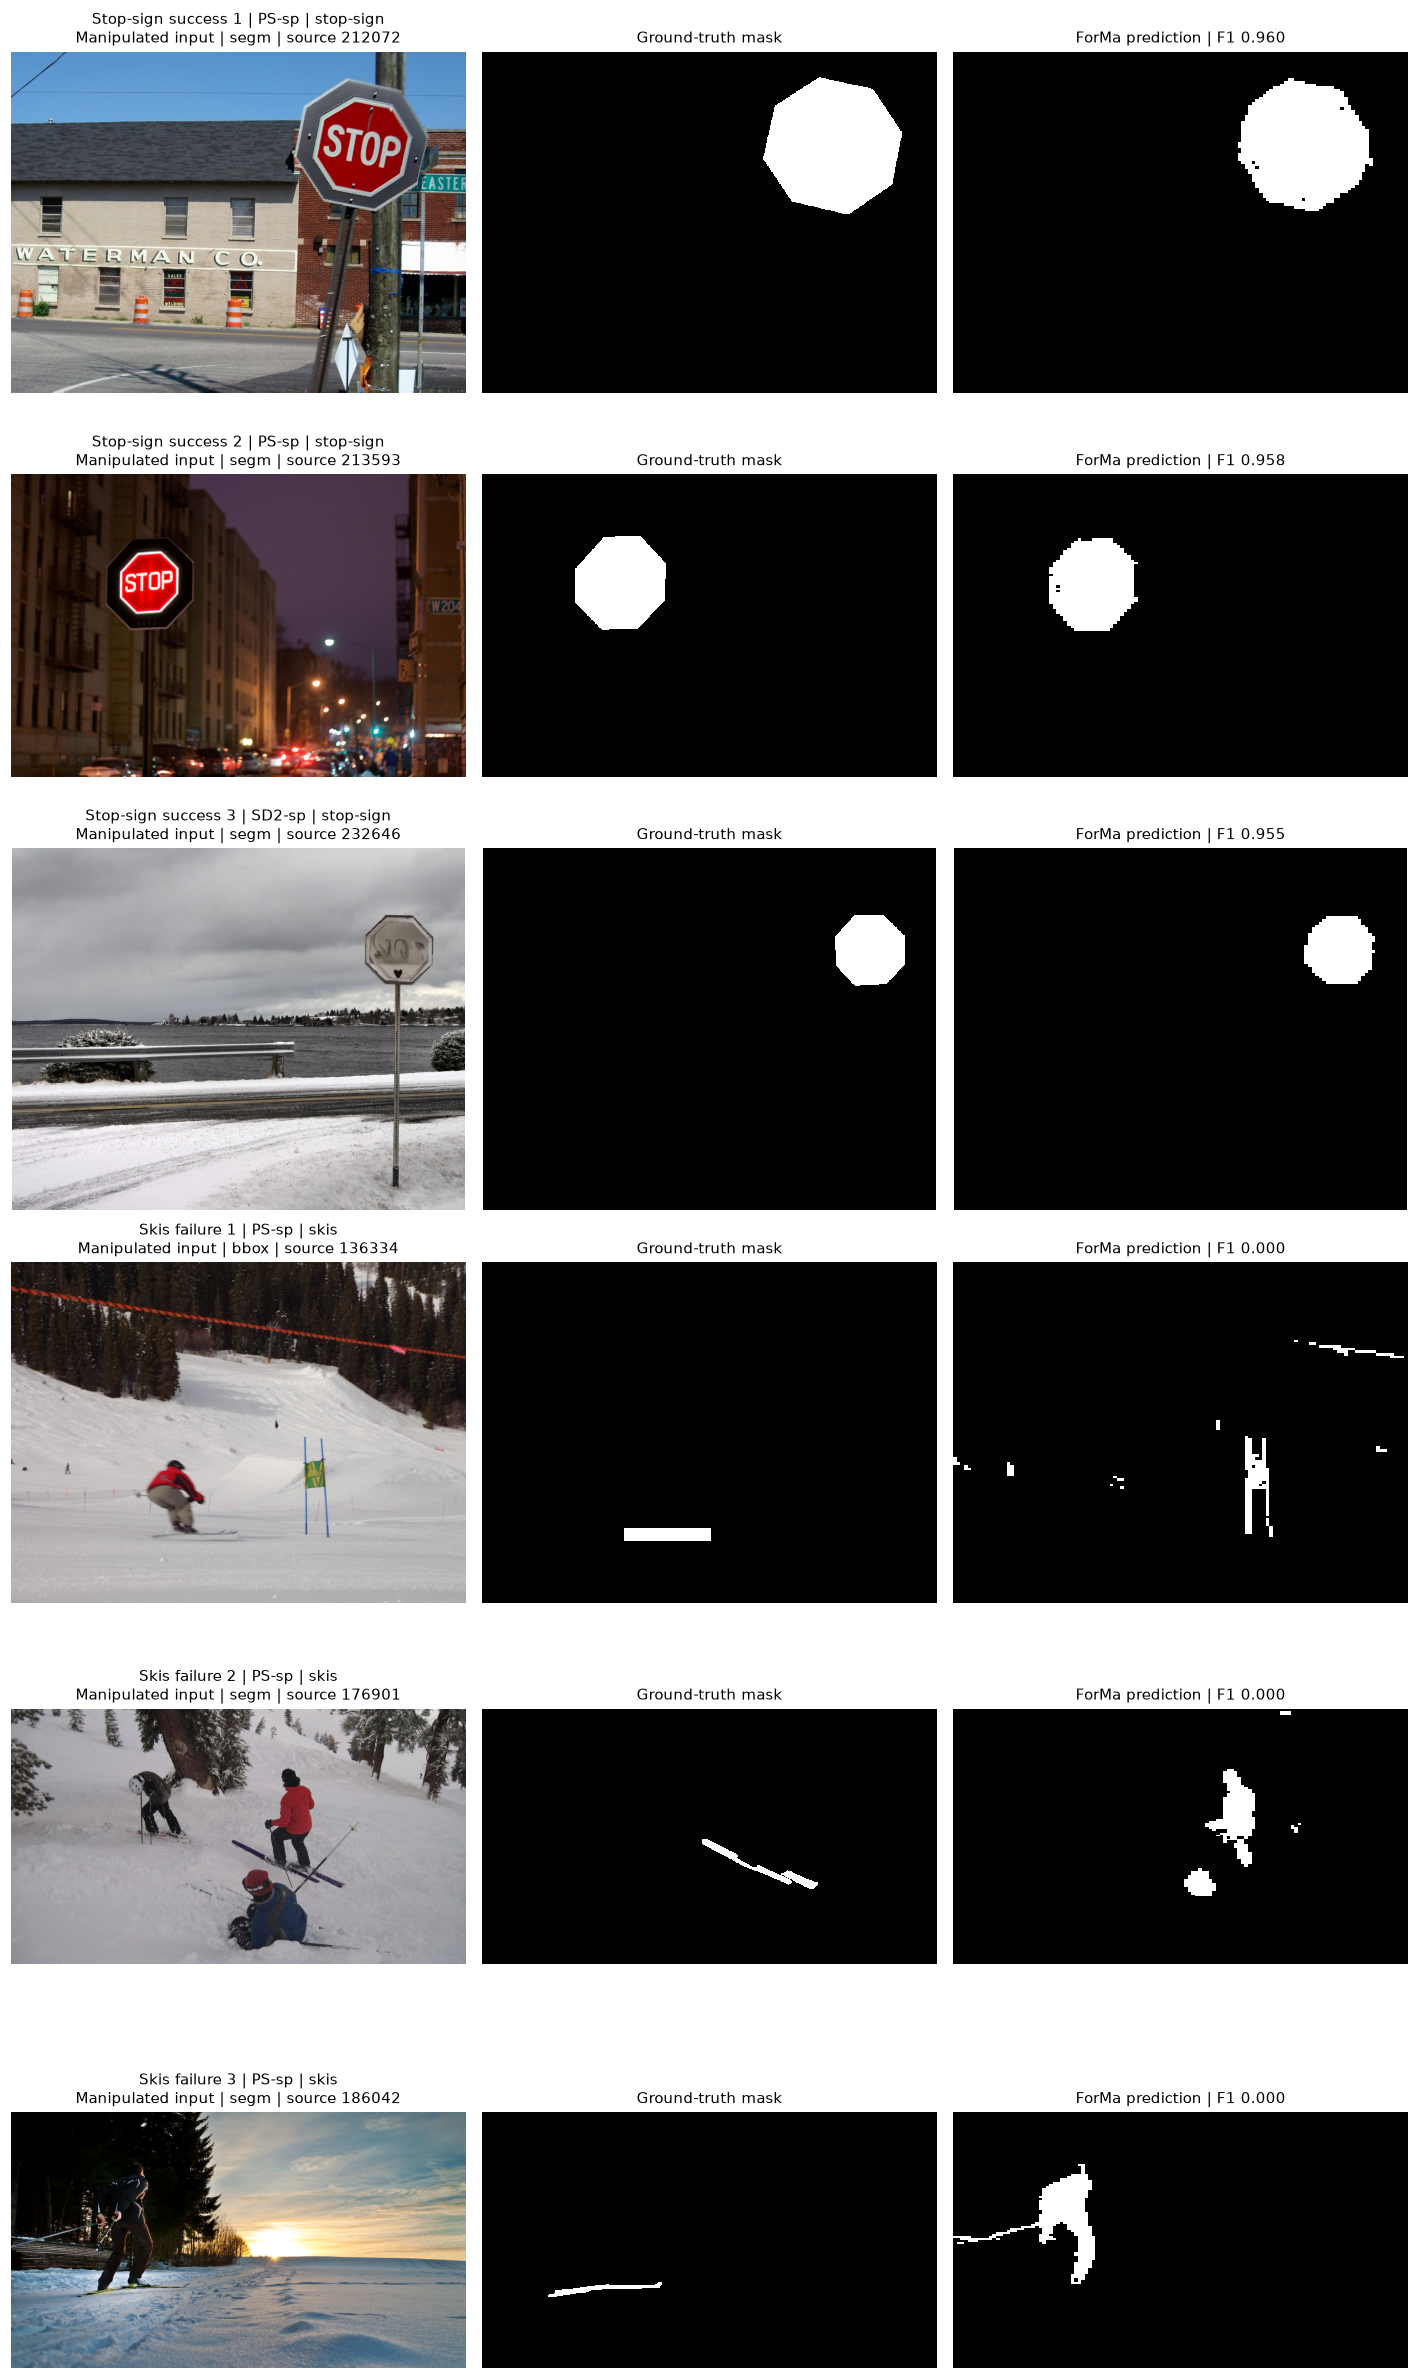

,selection,subset,mask_type,recorded_F1,visualized_F1,exact_counts_match
0,Stop-sign success 1,PS-sp,segm,0.959977,0.959977,True
1,Stop-sign success 2,PS-sp,segm,0.957528,0.957528,True
2,Stop-sign success 3,SD2-sp,segm,0.955208,0.955208,True
3,Skis failure 1,PS-sp,bbox,0.000000,0.000000,True
4,Skis failure 2,PS-sp,segm,0.000000,0.000000,True
5,Skis failure 3,PS-sp,segm,0.000000,0.000000,True


In [61]:
import hashlib
import json
import torch
from PIL import Image
from matplotlib.patches import Patch

if str(FORMA_DIR) not in sys.path:
    sys.path.insert(0, str(FORMA_DIR))
from inference import load_model, preprocess_image, run_inference, prediction_maps, sha256
from metrics import localization_metrics

def resolve_sample_path(row, field):
    recorded = Path(row[field])
    if recorded.is_file():
        return recorded
    # Fallback for a copied project whose workbook contains old absolute paths.
    if field == 'image_path':
        base = FORMA_DIR / 'data_tgif' / f'{row.subset.lower()}_testing' / 'testing'
        candidates = [base / name / row.image_name for name in [row.category, row.category.replace('-', ' ')]]
    else:
        base = FORMA_DIR / 'data_tgif' / 'masks_testing' / 'testing'
        candidates = [base / name / row.mask_name for name in [row.category, row.category.replace('-', ' ')]]
    for candidate in candidates:
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f'Cannot locate {field}: {recorded}')

weights = Path(WEIGHTS_OVERRIDE) if WEIGHTS_OVERRIDE else Path(samples.iloc[0].checkpoint_path)
if not weights.is_file() and WEIGHTS_OVERRIDE is None:
    weights = FORMA_DIR / 'ForMa_weights' / 'ForMa_weights.pth'
if not weights.is_file():
    raise FileNotFoundError(f'Checkpoint missing: {weights}')
if set(samples.checkpoint_sha256) != {sha256(weights)}:
    raise ValueError('Checkpoint hash differs from the evaluated checkpoint.')
device = ('cuda' if torch.cuda.is_available() else 'cpu') if DEVICE == 'auto' else DEVICE
if device == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('CUDA is unavailable. Set DEVICE to cpu.')
torch.set_num_threads(int(samples.iloc[0].threads))
cache_dir = FORMA_DIR / 'results' / 'visualization_predictions'
cache_dir.mkdir(parents=True, exist_ok=True)
model = None
fig, axes = plt.subplots(len(samples), 3, figsize=(13, 3.7 * len(samples)), squeeze=False)
checks = []
for axes_row, (_, row) in zip(axes, samples.iterrows()):
    image_path = resolve_sample_path(row, 'image_path')
    mask_path = resolve_sample_path(row, 'mask_path')
    if sha256(image_path) != row.image_sha256 or sha256(mask_path) != row.mask_sha256:
        raise ValueError(f'Input files changed since evaluation: {row.image_name}')
    tensor, image = preprocess_image(image_path, int(row.input_size))
    with Image.open(mask_path) as mask_image:
        target = np.asarray(mask_image.convert('L')) > int(row.ground_truth_threshold)
    if target.shape != (image.height, image.width):
        raise ValueError(f'Mask dimensions differ: {mask_path}')
    identity = json.dumps([row.sample_key, device, str(torch.__version__), 'visualization-v1'])
    cache_path = cache_dir / (hashlib.sha256(identity.encode()).hexdigest() + '.png')
    if cache_path.is_file():
        with Image.open(cache_path) as cached:
            prediction = np.asarray(cached.convert('L')) > 127
    else:
        if model is None:
            print(f'Loading ForMa on {device}...', flush=True)
            model = load_model(weights, device)
        print(f'Predicting {row.image_name}...', flush=True)
        logits = run_inference(model, tensor.to(device))
        _, prediction = prediction_maps(logits, image.size, float(row.prediction_threshold))
        Image.fromarray(prediction.astype(np.uint8) * 255).save(cache_path)
    scores = localization_metrics(prediction, target)
    matches = all(scores[k] == int(row[k]) for k in ['tp', 'fp', 'fn', 'tn'])
    checks.append({'selection': row.selection, 'subset': row.subset, 'mask_type': row.mask_type, 'recorded_F1': row.pixel_f1,
                   'visualized_F1': scores['pixel_f1'], 'exact_counts_match': matches})
    axes_row[0].imshow(image)
    axes_row[1].imshow(target, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
    axes_row[2].imshow(prediction, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
    f1_label = 'N/A' if scores['pixel_f1'] is None else f"{scores['pixel_f1']:.3f}"
    titles = [f'{row.selection} | {row.subset} | {row.category}\nManipulated input | {row.mask_type} | source {row.source_id}',
              'Ground-truth mask', f'ForMa prediction | F1 {f1_label}']
    for ax, title in zip(axes_row, titles):
        ax.set_title(title, fontsize=10)
        ax.axis('off')
finish(fig, 'stop_sign_three_successes_skis_three_failures')

display(pd.DataFrame(checks))
if not all(item['exact_counts_match'] for item in checks):
    print('Some recomputed counts differ from the workbook. Check device/software differences; these panels show the recomputed outputs.')
if model is not None:
    del model
    if device == 'cuda':
        torch.cuda.empty_cache()

## Final binary detection: authentic versus inpainted

This section uses **image-level classification**, distinct from pixel localization above. The detector marks an image inpainted when more than **1% of pixels** have ForMa manipulation probability above **0.5**. This is the previously chosen operating point; it was not optimized or calibrated on an independent validation set.

The combined test contains **4,116 manipulated images and 343 unique authentic originals**. Each generator-specific comparison uses its 2,058 manipulated images and the same 343 authentic images. Authentic images are counted once in the combined results. Precision, F1, accuracy and average precision depend on these class proportions. ROC-AUC and average precision use continuous predicted-area scores. These are point estimates, without confidence intervals; source variants are correlated.

Run these cells after `evaluate_full_detection.py` finishes. They require complete results and never substitute partial metrics. Figures are saved under `results/final_visualizations/detection/`.

In [62]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [Path.cwd(), Path.cwd() / 'ForMa',
              Path.cwd() / 'Group8_Benchmarking_inpainting_detection_with_small_models' / 'ForMa']
DETECTION_FORMA = next((p.resolve() for p in candidates if (p / 'evaluate_full_detection.py').is_file()), None)
if DETECTION_FORMA is None:
    raise FileNotFoundError('Open from the ForMa folder or project root.')
DETECTION_RESULTS = DETECTION_FORMA / 'results/full_detection/complete/threshold_0.01'
if not (DETECTION_RESULTS / 'report.json').is_file():
    cached = len(list((DETECTION_FORMA / 'results/full_detection/authentic_cache').glob('*/*.json')))
    raise FileNotFoundError(f'Full detection results are not ready yet ({cached} cached authentic scores across configurations). Wait for evaluate_full_detection.py to finish, then rerun this section.')
detection_report = json.loads((DETECTION_RESULTS / 'report.json').read_text())
if detection_report['status'] != 'complete':
    raise ValueError('This section requires complete detection results.')
detection_summary = pd.read_csv(DETECTION_RESULTS / 'detection_summary.csv')
detection_images = pd.read_csv(DETECTION_RESULTS / 'image_predictions.csv', dtype={'source_id': str})
assert len(detection_images) == 4459
assert (detection_images.y_true == 0).sum() == 343
assert (detection_images.y_true == 1).sum() == 4116
assert np.array_equal(detection_images.y_pred.to_numpy(), (detection_images.area_score > .01).astype(int).to_numpy())
DETECTION_NAMES = {'all': 'Combined', 'PS-sp': 'Photoshop / Firefly', 'SD2-sp': 'Stable Diffusion 2'}
DETECTION_COLORS = {'all': '#555555', 'PS-sp': '#c1b4c5', 'SD2-sp': '#771c30'}
DETECTION_METRICS = ['accuracy', 'precision', 'recall', 'f1', 'specificity', 'false_positive_rate',
                     'balanced_accuracy', 'roc_auc', 'average_precision']
DETECTION_LABELS = {'accuracy':'Accuracy', 'precision':'Precision', 'recall':'Recall', 'f1':'F1',
                    'specificity':'Specificity', 'false_positive_rate':'False-positive rate',
                    'balanced_accuracy':'Balanced accuracy', 'roc_auc':'ROC-AUC', 'average_precision':'Average precision'}
detection_overall = detection_summary[detection_summary.category == 'all'].set_index('subset').loc[['all','PS-sp','SD2-sp']]
print('Image-level detection; fixed image threshold = 0.01, pixel threshold = 0.5')
display(detection_overall[['images','authentic','inpainted',*DETECTION_METRICS]].rename(index=DETECTION_NAMES,columns=DETECTION_LABELS).round(4))
DETECTION_FIG_DIR = DETECTION_FORMA / 'results/final_visualizations/detection'
DETECTION_FIG_DIR.mkdir(parents=True, exist_ok=True)
def detection_finish(fig, name):
    fig.tight_layout()
    fig.savefig(DETECTION_FIG_DIR / f'{name}.png', dpi=180, bbox_inches='tight')
    plt.show()

Image-level detection; fixed image threshold = 0.01, pixel threshold = 0.5


,images,authentic,inpainted,Accuracy,Precision,Recall,F1,Specificity,False-positive rate,Balanced accuracy,ROC-AUC,Average precision
subset,,,,,,,,,,,,
Combined,4459,343,4116,0.7712,0.9227,0.8209,0.8689,0.1749,0.8251,0.4979,0.4813,0.9195
Photoshop / Firefly,2401,343,2058,0.7255,0.8560,0.8173,0.8362,0.1749,0.8251,0.4961,0.4761,0.8487
Stable Diffusion 2,2401,343,2058,0.7318,0.8571,0.8246,0.8405,0.1749,0.8251,0.4998,0.4864,0.8534


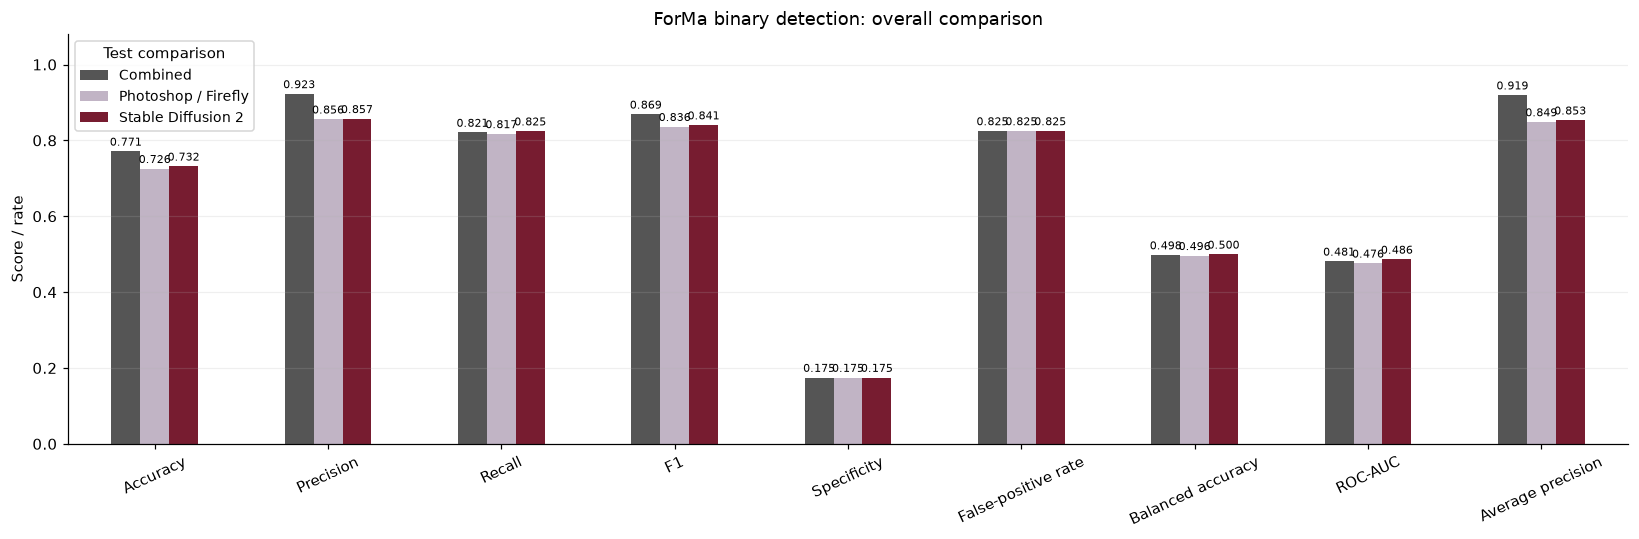

Lower false-positive rate is better; all other displayed metrics are higher-is-better.


In [63]:
fig, ax = plt.subplots(figsize=(15, 5))
detection_overall[DETECTION_METRICS].rename(index=DETECTION_NAMES, columns=DETECTION_LABELS).T.plot.bar(
    ax=ax, color=[DETECTION_COLORS[s] for s in detection_overall.index], rot=25)
ax.set(title='ForMa binary detection: overall comparison', ylabel='Score / rate', ylim=(0, 1.08))
ax.grid(axis='y', alpha=.2)
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.3f', fontsize=7, padding=2)
ax.legend(title='Test comparison', fontsize=9)
detection_finish(fig, 'overall_detection_metrics')
print('Lower false-positive rate is better; all other displayed metrics are higher-is-better.')

### Detection by category and generator

Each pair of bars compares that generator's manipulated images against the same authentic images in the category. Specificity and false-positive rate are therefore identical between generator comparisons when they share the same negatives and decision rule. Category F1 here is binary classification F1 from image counts, not mean localization F1.

,category,subset,images,authentic,inpainted,Accuracy,Precision,Recall,F1,Specificity,False-positive rate,Balanced accuracy,ROC-AUC,Average precision
15,airplane,PS-sp,196,28,168,0.6684,0.8552,0.7381,0.7923,0.2500,0.7500,0.4940,0.4960,0.8615
16,bear,PS-sp,140,20,120,0.7714,0.8667,0.8667,0.8667,0.2000,0.8000,0.5333,0.5133,0.8730
17,elephant,PS-sp,245,35,210,0.7755,0.8605,0.8810,0.8706,0.1429,0.8571,0.5119,0.5159,0.8596
18,hair-drier,PS-sp,14,2,12,0.8571,0.8571,1.0000,0.9231,0.0000,1.0000,0.5000,0.5417,0.8823
19,kite,PS-sp,217,31,186,0.6221,0.8467,0.6828,0.7560,0.2581,0.7419,0.4704,0.3999,0.8279
20,scissors,PS-sp,63,9,54,0.7937,0.8596,0.9074,0.8829,0.1111,0.8889,0.5093,0.5442,0.8764
21,sheep,PS-sp,196,28,168,0.6939,0.8750,0.7500,0.8077,0.3571,0.6429,0.5536,0.5057,0.8565
22,skis,PS-sp,308,44,264,0.6656,0.8643,0.7235,0.7876,0.3182,0.6818,0.5208,0.5277,0.8656
23,snowboard,PS-sp,140,20,120,0.8143,0.8507,0.9500,0.8976,0.0000,1.0000,0.4750,0.4527,0.8533
24,sports-ball,PS-sp,154,22,132,0.6623,0.8333,0.7576,0.7937,0.0909,0.9091,0.4242,0.4559,0.8553


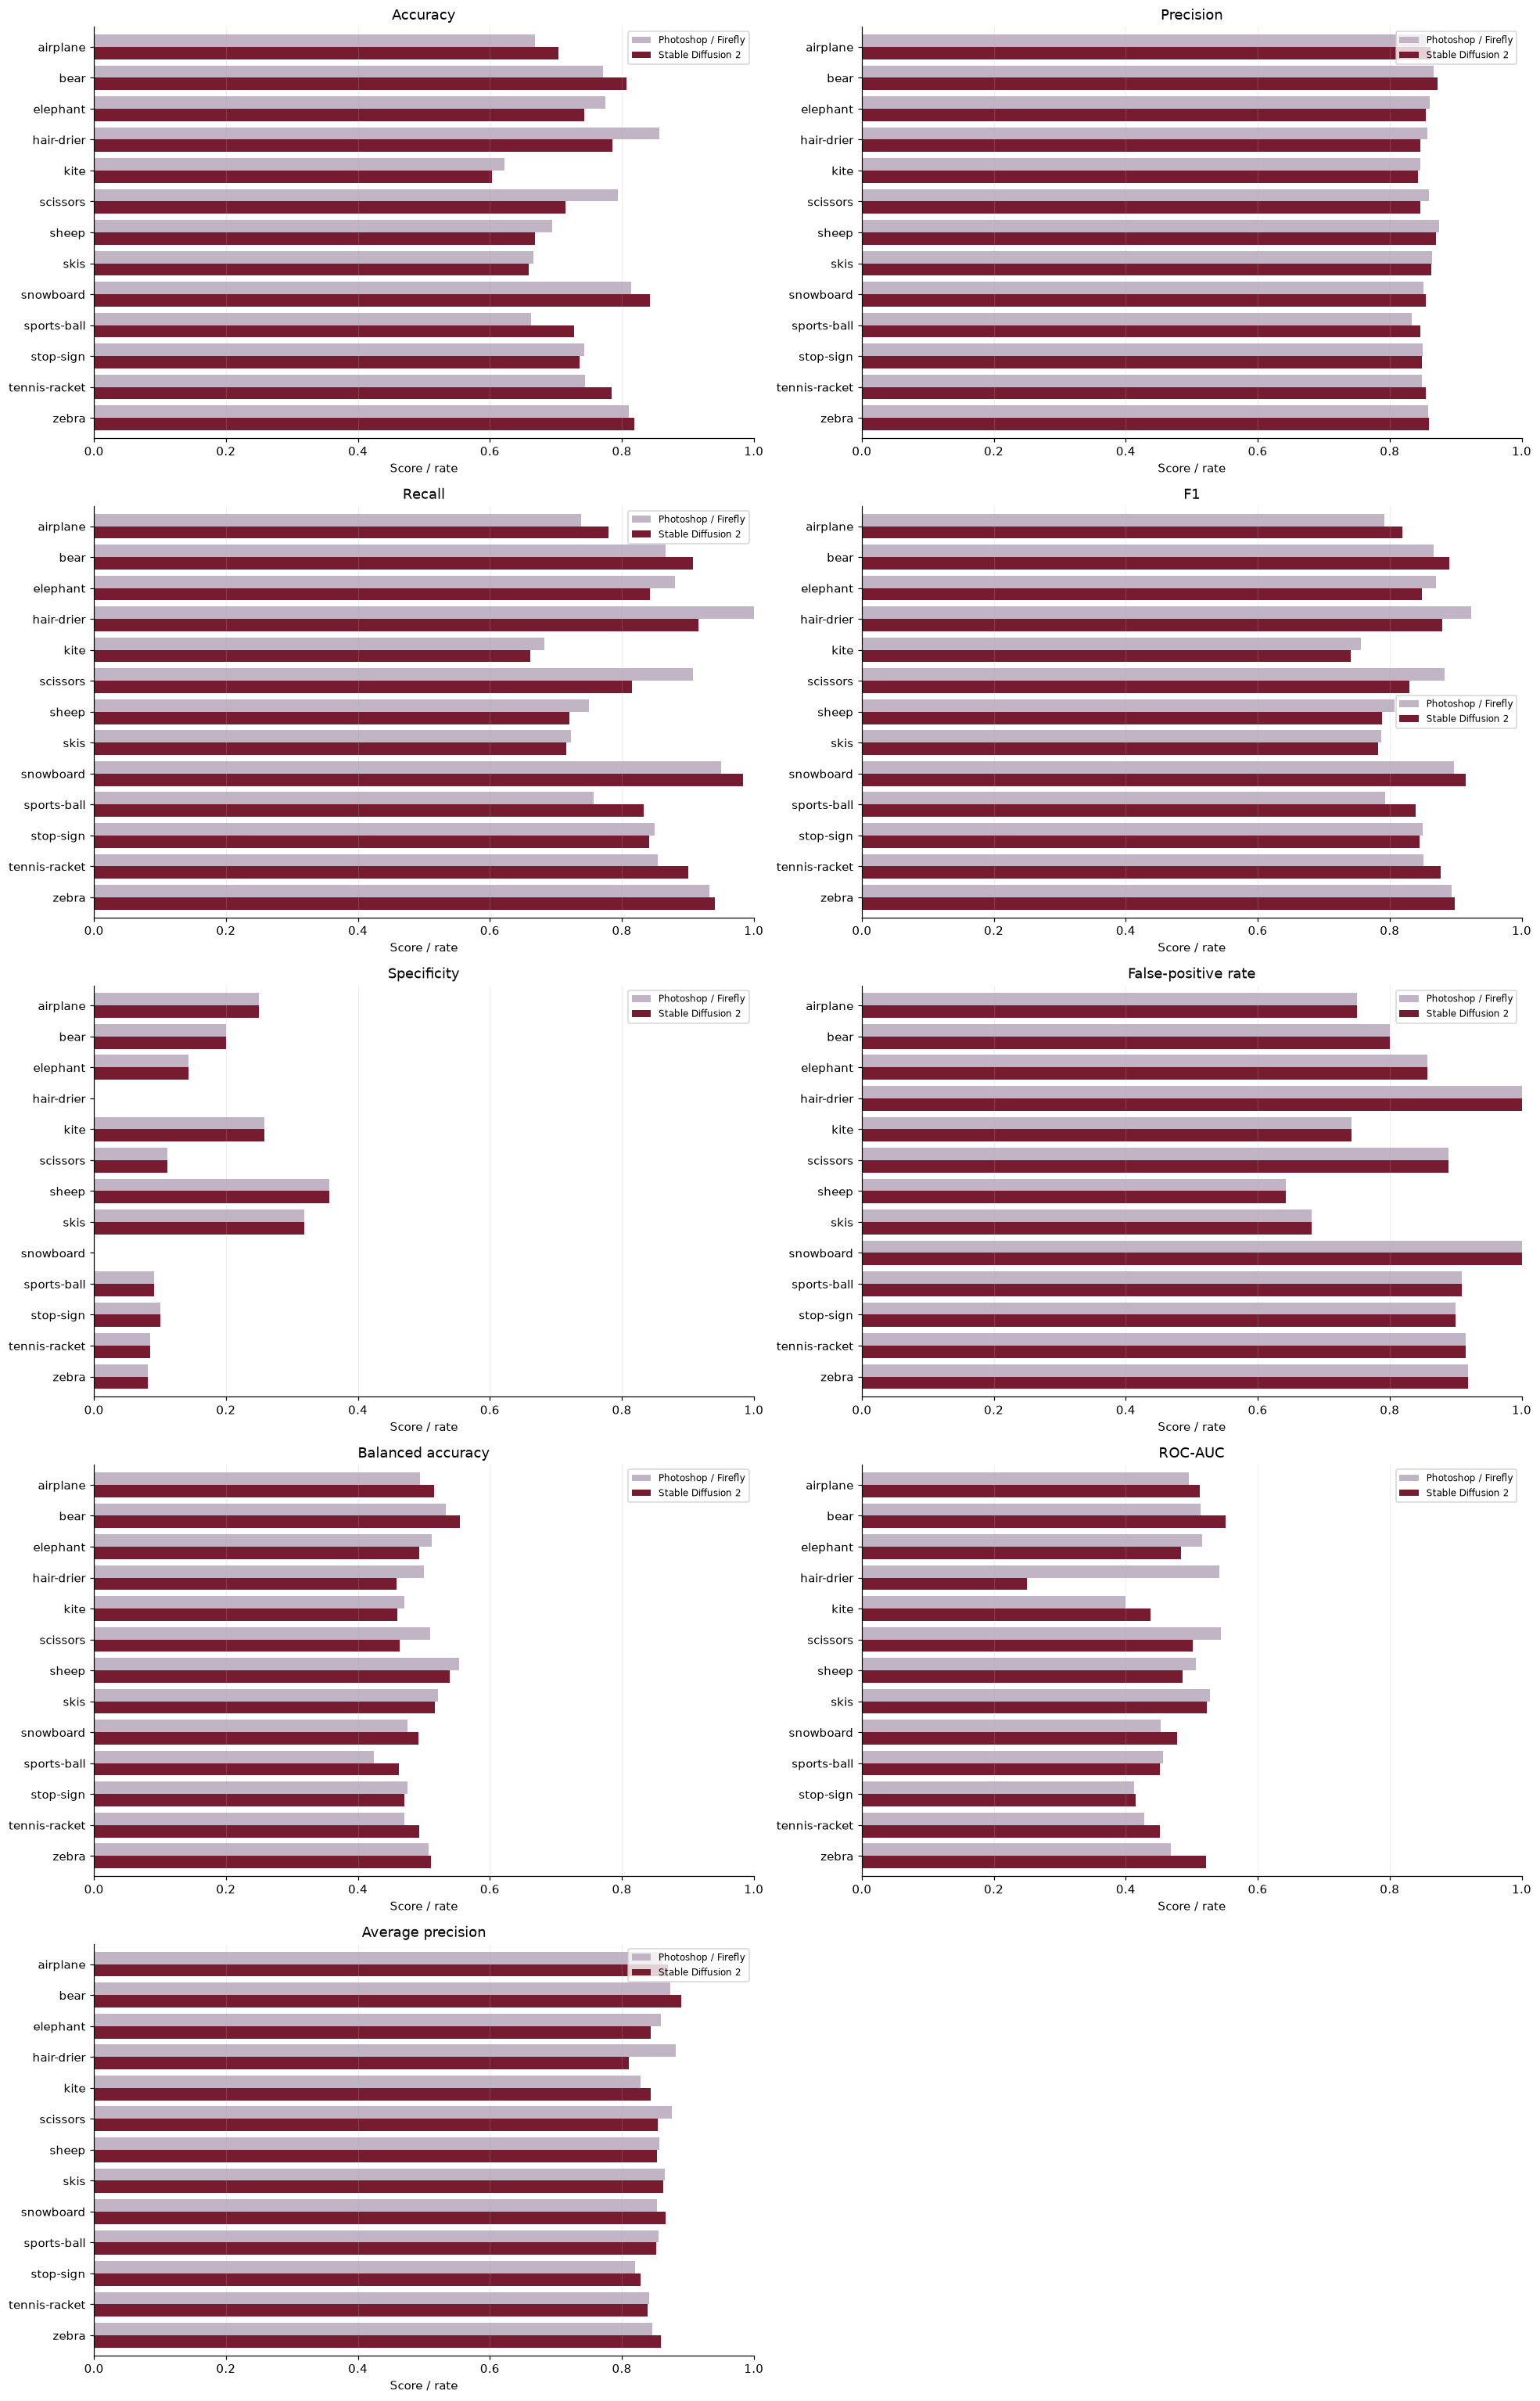

In [64]:
category_detection = detection_summary[(detection_summary.category != 'all') & (detection_summary.subset != 'all')]
display(category_detection[['category','subset','images','authentic','inpainted',*DETECTION_METRICS]].rename(columns=DETECTION_LABELS).round(4))
fig, axes = plt.subplots(5, 2, figsize=(18, 28))
for ax, metric in zip(axes.flat, DETECTION_METRICS):
    table = category_detection.pivot(index='category', columns='subset', values=metric).reindex(columns=['PS-sp','SD2-sp']).sort_index()
    table.rename(columns=DETECTION_NAMES).plot.barh(ax=ax, color=[DETECTION_COLORS['PS-sp'],DETECTION_COLORS['SD2-sp']], width=.8)
    ax.set(title=DETECTION_LABELS[metric], xlabel='Score / rate', ylabel='', xlim=(0, 1))
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=.2)
    ax.legend(fontsize=8)
axes.flat[-1].axis('off')
detection_finish(fig, 'category_detection_metrics')

### Confusion matrices

Rows are true labels and columns are predicted labels. Color represents the fraction within each true class; annotations show both counts and percentages. The combined matrix counts each authentic original once. Adding the two generator matrices would incorrectly count originals twice.

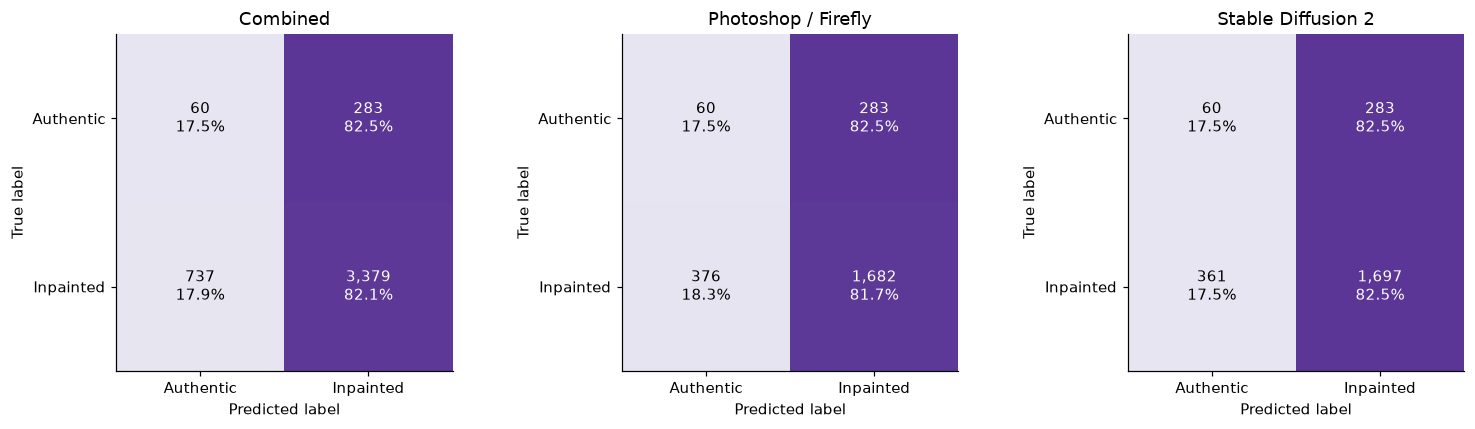

In [65]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (subset, row) in zip(axes, detection_overall.iterrows()):
    matrix = np.array([[row.tn,row.fp],[row.fn,row.tp]], dtype=int)
    normalized = matrix / matrix.sum(axis=1, keepdims=True)
    ax.imshow(normalized, cmap='Purples', vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j,i,f'{matrix[i,j]:,}\n{normalized[i,j]:.1%}',ha='center',va='center',
                    color='white' if normalized[i,j]>.6 else 'black')
    ax.set_xticks([0,1],['Authentic','Inpainted'])
    ax.set_yticks([0,1],['Authentic','Inpainted'])
    ax.set(title=DETECTION_NAMES[subset],xlabel='Predicted label',ylabel='True label')
detection_finish(fig, 'detection_confusion_matrices')